# Behavior Analysis - Model Training

Trains the behavior-category ML model on the hand-labelled dataset at
`backend/datasets/journal/student_behavior.xlsx`, compares a few candidate
models with cross-validation, picks the best one, evaluates it on a held-out
test split, and saves the trained model plus a metrics report under
`backend/trained-models/behavior-analysis/`.

This notebook is standalone research/training code - it does not import from
the `app` package. The live backend only depends on the saved model file
(`behavior_model.joblib`), loaded by `app/services/journal/ml/behavior_predictor.py`.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## Paths and settings

In [2]:
# Run this notebook from its own folder (backend/ml_scripts/journal/behavior_analyze/) -
# that's Jupyter's default working directory, so backend/ is 3 levels up.
BACKEND_ROOT = Path.cwd().resolve().parents[2]
DATASET_PATH = BACKEND_ROOT / "datasets" / "journal" / "student_behavior.xlsx"
OUTPUT_DIR = BACKEND_ROOT / "trained-models" / "behavior-analysis"
MODEL_PATH = OUTPUT_DIR / "behavior_model.joblib"
RANDOM_STATE = 42

print("Backend root:", BACKEND_ROOT)
print("Dataset path:", DATASET_PATH)
print("Output dir:", OUTPUT_DIR)

Backend root: F:\Smart-Uni-Guide\backend
Dataset path: F:\Smart-Uni-Guide\backend\datasets\journal\student_behavior.xlsx
Output dir: F:\Smart-Uni-Guide\backend\trained-models\behavior-analysis


## Feature columns

Duplicated here (not imported from `app`) so this notebook stays standalone,
matching the rest of this project's `ml_scripts/` training code. This list
must stay in sync with `app/services/journal/ml/feature_extraction.py`'s
`FEATURE_NAMES` - that is the single source of truth the live predictor uses.

In [3]:
FEATURE_NAMES = [
    "study_hours_avg_per_day",
    "study_hours_last_14_days",
    "total_sessions_last_14_days",
    "active_days_last_14_days",
    "activity_frequency",
    "nearest_deadline_days",
    "due_within_3_days",
    "due_within_7_days",
    "overdue",
    "total_tasks",
    "completed_tasks",
    "nearest_exam_days",
    "exams_within_3_days",
    "exams_within_7_days",
    "total_upcoming_exams",
    "engagement_high",
    "engagement_medium",
    "engagement_low",
]

## Candidate models to compare

In [4]:
CANDIDATES = {
    "random_forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=2, random_state=RANDOM_STATE
    ),
    "gradient_boosting": GradientBoostingClassifier(
        n_estimators=150, max_depth=3, learning_rate=0.1, random_state=RANDOM_STATE
    ),
    "logistic_regression": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        ]
    ),
}

## Load dataset

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(DATASET_PATH)
missing = [c for c in FEATURE_NAMES if c not in df.columns]
if missing:
    raise ValueError(f"Dataset is missing expected feature columns: {missing}")

X = df[FEATURE_NAMES]
y = df["label_category"]

print(f"Loaded {len(X)} labelled rows from {DATASET_PATH.name}")
print(f"Class balance:\n{y.value_counts()}")

Loaded 280 labelled rows from student_behavior.xlsx
Class balance:
label_category
Low Engagement Student    56
Consistent Learner        56
Highly Engaged Student    56
Overloaded Student        56
Last-Minute Learner       56
Name: count, dtype: int64


## Train/test split

Stratified 75/25 split so every class keeps the same proportion in both sets.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print(f"Train rows: {len(X_train)}, Test rows: {len(X_test)}")

Train rows: 210, Test rows: 70


## Cross-validate each candidate model

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, estimator in CANDIDATES.items():
    scores = cross_val_score(estimator, X_train, y_train, cv=cv, scoring="accuracy")
    cv_results[name] = {"mean": float(scores.mean()), "std": float(scores.std())}
    print(f"{name}: CV accuracy {scores.mean():.3f} (+/- {scores.std():.3f})")

best_name = max(cv_results, key=lambda n: cv_results[n]["mean"])
best_model = CANDIDATES[best_name]
print(f"\nBest candidate: {best_name}")

random_forest: CV accuracy 0.971 (+/- 0.023)


gradient_boosting: CV accuracy 0.971 (+/- 0.010)
logistic_regression: CV accuracy 0.957 (+/- 0.010)

Best candidate: random_forest


## Train the best model and evaluate on the held-out test set

In [8]:
best_model.fit(X_train, y_train)
predictions = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, predictions)
test_f1_macro = f1_score(y_test, predictions, average="macro")
report = classification_report(y_test, predictions, output_dict=True)
report_text = classification_report(y_test, predictions)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test macro F1: {test_f1_macro:.3f}")
print(report_text)

Test accuracy: 0.929
Test macro F1: 0.929
                        precision    recall  f1-score   support

    Consistent Learner       0.85      0.79      0.81        14
Highly Engaged Student       0.81      0.93      0.87        14
   Last-Minute Learner       1.00      1.00      1.00        14
Low Engagement Student       1.00      0.93      0.96        14
    Overloaded Student       1.00      1.00      1.00        14

              accuracy                           0.93        70
             macro avg       0.93      0.93      0.93        70
          weighted avg       0.93      0.93      0.93        70



## Confusion matrix

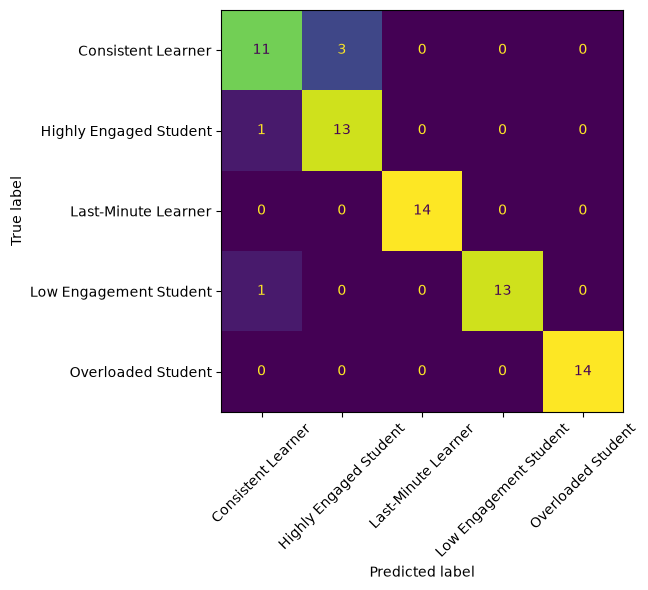

In [9]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, predictions, labels=labels)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, xticks_rotation=45, colorbar=False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## Feature importance

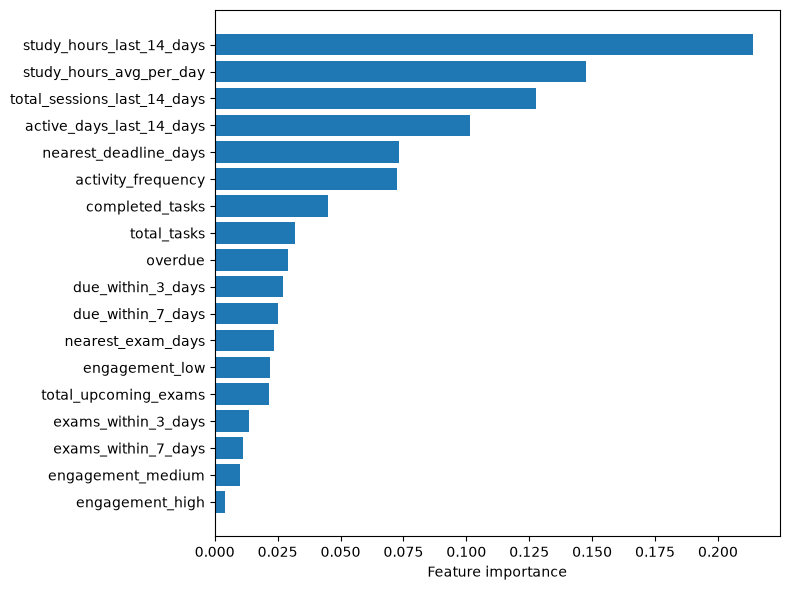

In [10]:
if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
    order = sorted(range(len(FEATURE_NAMES)), key=lambda i: importances[i], reverse=True)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh([FEATURE_NAMES[i] for i in order][::-1], [importances[i] for i in order][::-1])
    ax.set_xlabel("Feature importance")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "feature_importance.png", dpi=150)
    plt.show()

## Final refit and save

Retrains the chosen model on the full labelled dataset (train+test) so the
shipped model uses every row. The metrics above (from the held-out split)
are what's reported - this refit is only for the model that ships.

In [11]:
final_model = CANDIDATES[best_name]
final_model.fit(X, y)

joblib.dump(
    {
        "model": final_model,
        "feature_names": FEATURE_NAMES,
        "classes": sorted(y.unique()),
        "model_name": best_name,
        "trained_at": datetime.now(timezone.utc).isoformat(),
    },
    MODEL_PATH,
)
print(f"Saved model to {MODEL_PATH}")

Saved model to F:\Smart-Uni-Guide\backend\trained-models\behavior-analysis\behavior_model.joblib


## Save metrics report

In [12]:
metrics = {
    "trained_at": datetime.now(timezone.utc).isoformat(),
    "dataset_rows": len(X),
    "model_selected": best_name,
    "cross_validation": cv_results,
    "test_set_size": len(X_test),
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_f1_macro,
    "classification_report": report,
}
with open(OUTPUT_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
with open(OUTPUT_DIR / "classification_report.txt", "w") as f:
    f.write(f"Model: {best_name}\n")
    f.write(f"Test accuracy: {test_accuracy:.3f}\nTest macro F1: {test_f1_macro:.3f}\n\n")
    f.write(report_text)
print(f"Saved metrics to {OUTPUT_DIR}")

Saved metrics to F:\Smart-Uni-Guide\backend\trained-models\behavior-analysis
